In [1]:
import os
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer

In [2]:
# Load CKD training data, test data, and model

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

PROCESSED_DIR = os.path.join(
    BASE_DIR, "datasets", "processed", "ckd"
)

MODEL_DIR = os.path.join(
    BASE_DIR, "models", "ckd"
)

X_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_train.csv")
)

X_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_test.csv")
)

ckd_model = joblib.load(
    os.path.join(MODEL_DIR, "best_model.pkl")
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Model:", type(ckd_model).__name__)

X_train shape: (319, 24)
X_test shape: (80, 24)
Model: RandomForestClassifier


In [3]:
# Create LIME explainer

explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["Not CKD", "CKD"],
    mode="classification",
    random_state=42
)

print("CKD LIME explainer created successfully!")

CKD LIME explainer created successfully!


In [4]:
# Generate LIME explanation for one CKD patient

patient_index = 0
patient = X_test.iloc[patient_index].values

lime_explanation = explainer.explain_instance(
    patient,
    ckd_model.predict_proba,
    num_features=10
)

print("CKD LIME explanation generated successfully!")
print("\nTop contributing features:")

for feature, weight in lime_explanation.as_list():
    print(f"{feature}: {weight:.4f}")

CKD LIME explanation generated successfully!

Top contributing features:
hemo > 0.81: -0.1008
dm <= -0.69: -0.0731
sc <= -0.36: -0.0679
rbcc > 0.54: -0.0654
htn <= -0.76: -0.0549
-0.51 < sg <= 0.42: -0.0474
pcv > 0.63: -0.0455
su <= -0.35: -0.0222
bgr <= -0.56: -0.0193
pc <= -0.50: -0.0180


d:\Explainable-AI-CDSS\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


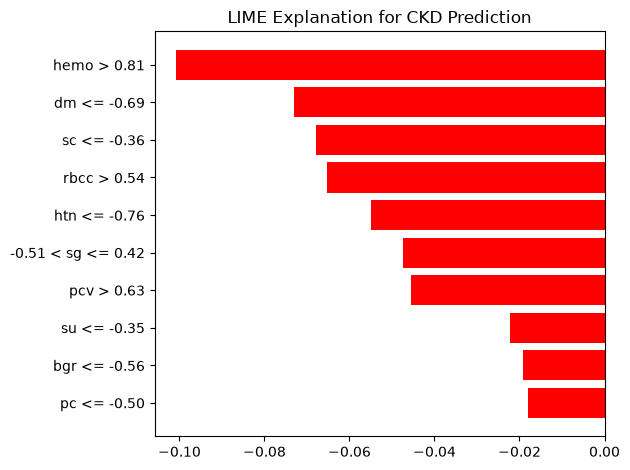

In [5]:
# Visualize CKD LIME explanation

fig = lime_explanation.as_pyplot_figure()

plt.title("LIME Explanation for CKD Prediction")
plt.tight_layout()
plt.show()

In [6]:
# Save CKD LIME explanation

LIME_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "ckd"
)

lime_results = pd.DataFrame(
    lime_explanation.as_list(),
    columns=["Feature", "LIME Weight"]
)

lime_results.to_csv(
    os.path.join(LIME_DIR, "lime_explanation.csv"),
    index=False
)

print("CKD LIME explanation saved successfully!")

CKD LIME explanation saved successfully!


In [7]:
# Verify saved LIME explanation

lime_file = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "ckd",
    "lime_explanation.csv"
)

if os.path.exists(lime_file):
    print("✓ CKD LIME explanation saved successfully")
    print("\nTop LIME features:")
    print(lime_results)
else:
    print("✗ LIME explanation file not found")

✓ CKD LIME explanation saved successfully

Top LIME features:
              Feature  LIME Weight
0         hemo > 0.81    -0.100767
1         dm <= -0.69    -0.073143
2         sc <= -0.36    -0.067883
3         rbcc > 0.54    -0.065370
4        htn <= -0.76    -0.054892
5  -0.51 < sg <= 0.42    -0.047395
6          pcv > 0.63    -0.045499
7         su <= -0.35    -0.022224
8        bgr <= -0.56    -0.019258
9         pc <= -0.50    -0.017957


In [12]:
# Verify CKD explainability files

processed_dir = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "ckd"
)

files = [
    "shap_feature_importance.csv",
    "lime_explanation.csv"
]

print("CKD Explainability Files")
print("-" * 35)

for file_name in files:
    file_path = os.path.join(processed_dir, file_name)

    if os.path.exists(file_path):
        print(f"✓ {file_name}")
    else:
        print(f"✗ {file_name}")

print("\n✓ CKD SHAP completed")
print("✓ CKD LIME completed")
print("✓ CKD explainability pipeline completed")

CKD Explainability Files
-----------------------------------
✓ shap_feature_importance.csv
✓ lime_explanation.csv

✓ CKD SHAP completed
✓ CKD LIME completed
✓ CKD explainability pipeline completed
